In [1]:
import sys
src_path = "/home/souvik/codes/foresee-main"
sys.path.append(src_path)

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect

In [2]:
from src_modified.foresee import Foresee, Utility, Model
foresee = Foresee()

energy = "100"
modelname="U1_slzplln"
model = Model(modelname, path="./")

In [3]:
sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast 

In [4]:
model.add_production_2bodydecay(
    pid0 = "111",
    pid1 = "22",
    br = "2*0.99 * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
#     br = "2*0.99 * (coupling)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50
)

model.add_production_2bodydecay(
    pid0 = "221",
    pid1 = "22",
    br = "2*0.25*0.39  * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
#     br = "2*0.39 * (coupling)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50, 
)

In [5]:
masses_brem = [ 
   0.01  ,  0.0126,  0.0158,  0.02  ,  0.0251,  0.0316,  0.0398,
   0.0501,  0.0631,  0.0794,  0.1   ,  0.1122,  0.1259,  0.10013,
   0.1585,  0.1778,  0.1995,  0.2239,  0.2512,  0.2818,  0.3162,
   0.3548,  0.3981,  0.4467,  0.5012,  0.5623,  0.6026,  0.631 ,
   0.6457,  0.6607,  0.6761,  0.6918,  0.7079,  0.7244,  0.7413,
   0.7586,  0.7762,  0.7943,  0.8128,  0.8318,  0.8511,  0.871 ,
   0.8913,  0.912 ,  0.9333,  0.955 ,  0.9772,  1.    ,  1.122 ,
   1.2589,  1.4125,  1.5849,  1.7783,  1.9953,  2.2387,  2.5119,
   2.8184,  3.1623,  3.9811,  5.0119,  6.3096,  7.9433, 10.    
]

model.add_production_direct(
    label = "Brem",
    energy = energy,
    condition = None, #"1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_brem,
)

In [6]:
masses1 = np.logspace(-3, np.log10(4), 60)
masses2 = np.logspace(np.log10(4),np.log10(6), 40)
masses3 = np.logspace(np.log10(6), 1, 10)
masses = np.array(sorted(list(set(np.concatenate((masses1,masses2,masses3))))))
foresee.set_model(model=model)
# for mass in masses:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, luminosity=3000, mincount=0,
#                                           do_plot=False, stat_cuts=None, save_file=True)

In [7]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "default_LLP2_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=1, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(50)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min 5s, sys: 371 ms, total: 9min 5s
Wall time: 9min 10s


In [8]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 13.2 s, sys: 520 ms, total: 13.7 s
Wall time: 13.7 s


/home/souvik/anaconda3/lib/python3.11/site-packages/numpy/lib/npyio.py:521: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.asanyarray(arr)


In [9]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/3928670568.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


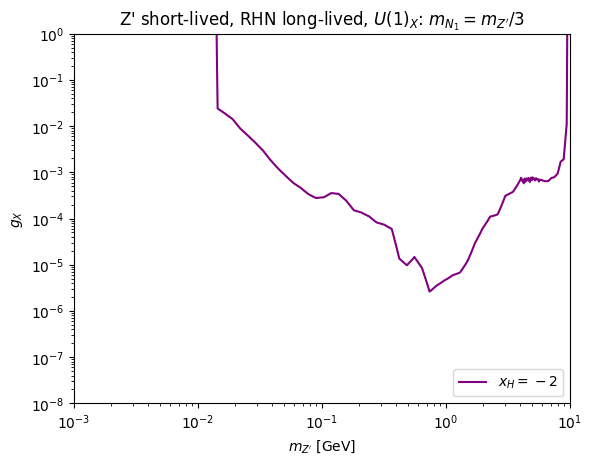

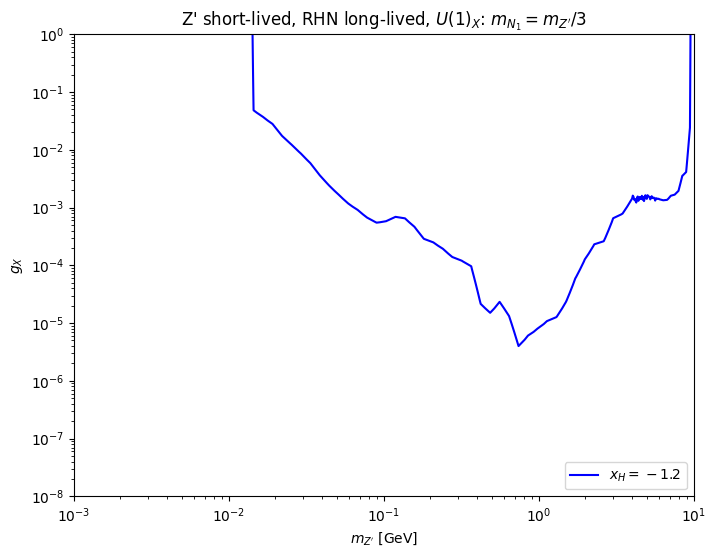

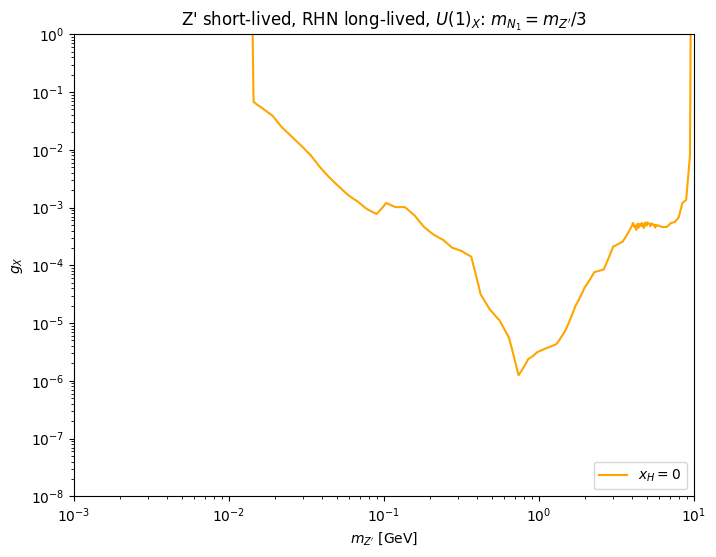

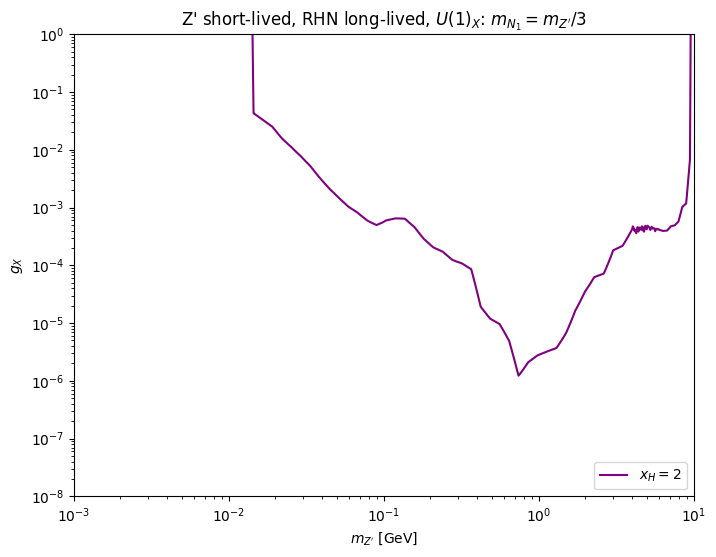

In [10]:
setups = [
         ["100TeV_default_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_default_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    # ax.set_ylim(1e-6, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, $U(1)_X$: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_e/plots/"+filename+".png")

In [11]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "default_LLP2_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=2, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(50)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min 3s, sys: 100 ms, total: 9min 3s
Wall time: 9min 3s


In [12]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 24.1 s, sys: 940 ms, total: 25 s
Wall time: 25.1 s


In [13]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/2792637245.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


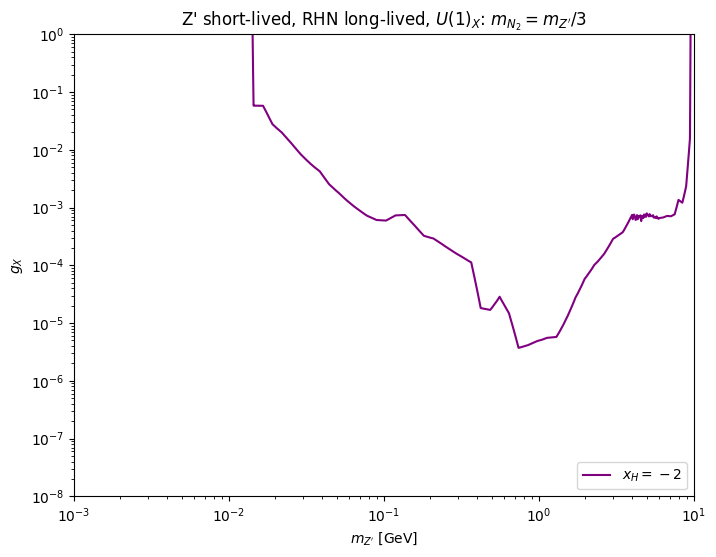

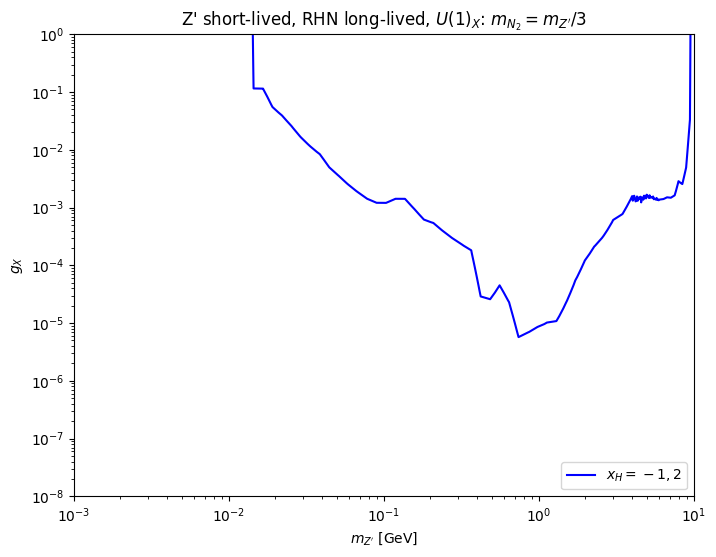

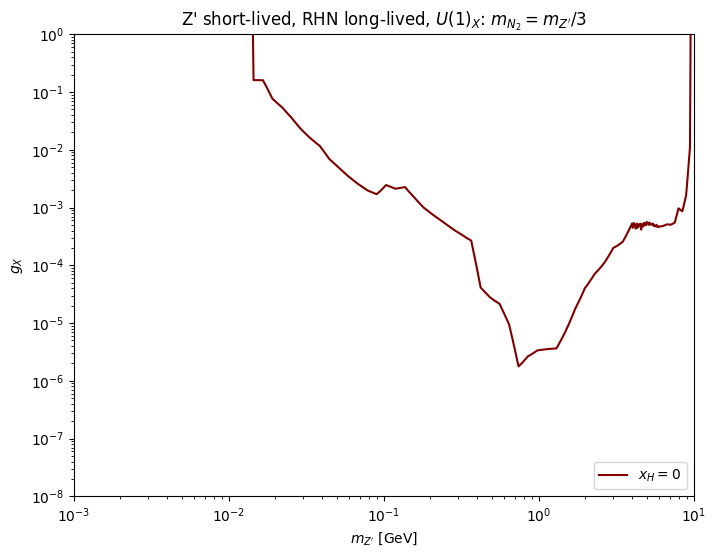

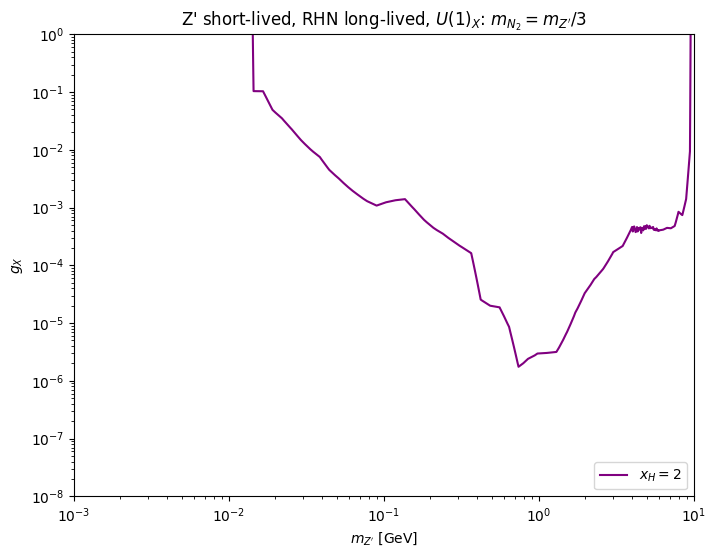

In [14]:
setups = [
         ["100TeV_default_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_12n.npy",    r"$x_H = -1,2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP2_0.npy",    r"$x_H = 0$"  , "maroon", "solid", 0., 3],#*150/3000]]  
         ["100TeV_default_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-8, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, $U(1)_X$: $m_{N_2} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_mu/plots/"+filename+".png")

In [15]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "alternative_LLP2_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=1, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(50)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min, sys: 47.9 ms, total: 9min
Wall time: 9min 1s


In [16]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 31.8 s, sys: 1.24 s, total: 33 s
Wall time: 33 s


In [17]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/3611872637.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


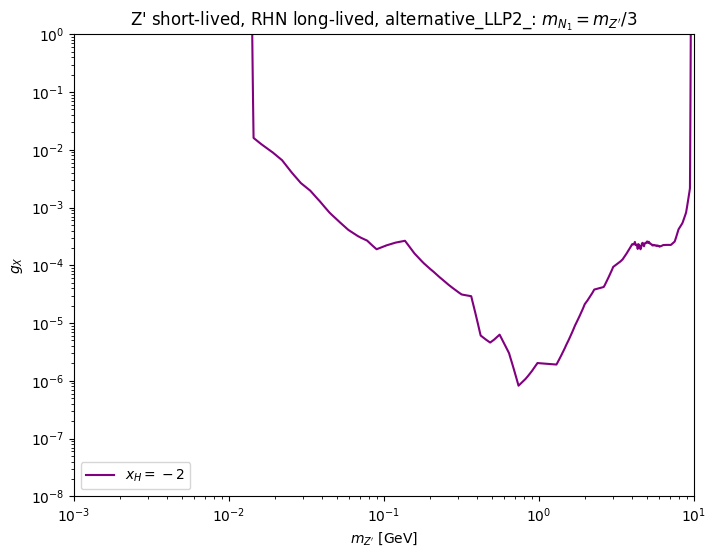

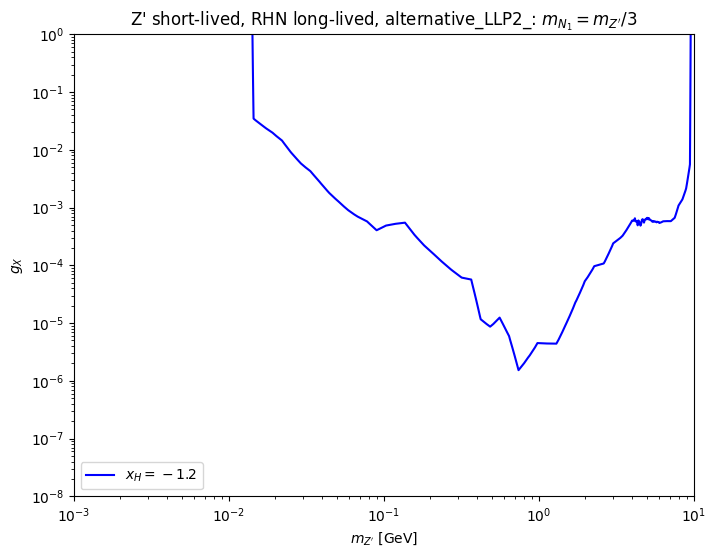

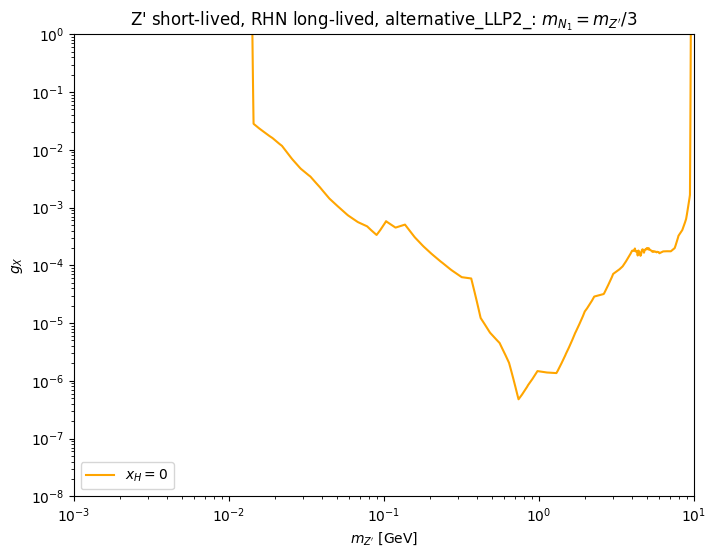

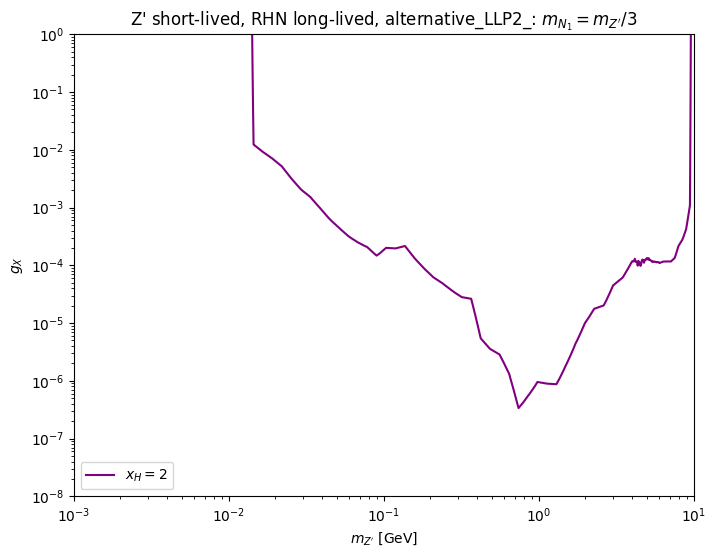

In [18]:
setups = [
         ["100TeV_alternative_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000], 
         ["100TeV_alternative_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-8, 1)
    ax.legend(loc = "lower left")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative_LLP2_: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_e/plots/"+filename+".png")

In [19]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
energy, setup, name = '100', "alternative_LLP2_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=2, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(50)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min 8s, sys: 120 ms, total: 9min 9s
Wall time: 9min 9s


In [20]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 31.9 s, sys: 1.31 s, total: 33.2 s
Wall time: 33.2 s


In [21]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/3588637099.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


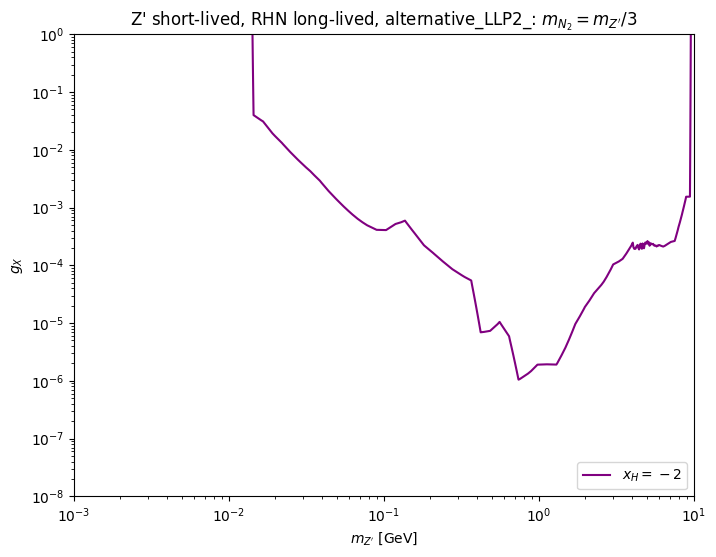

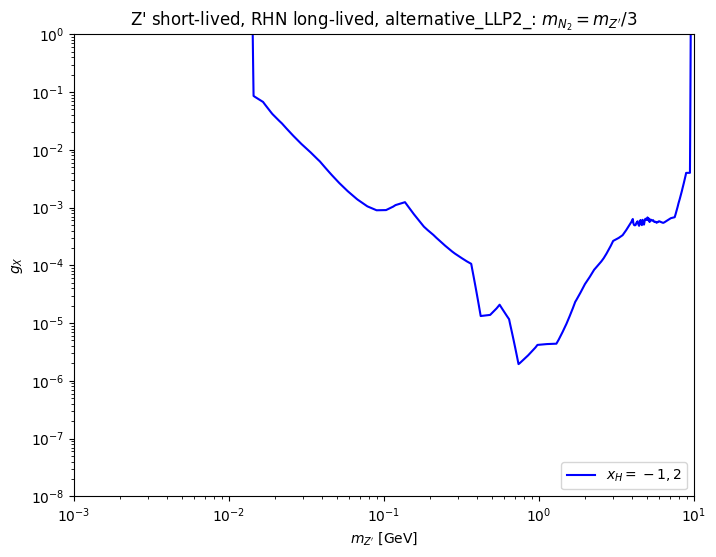

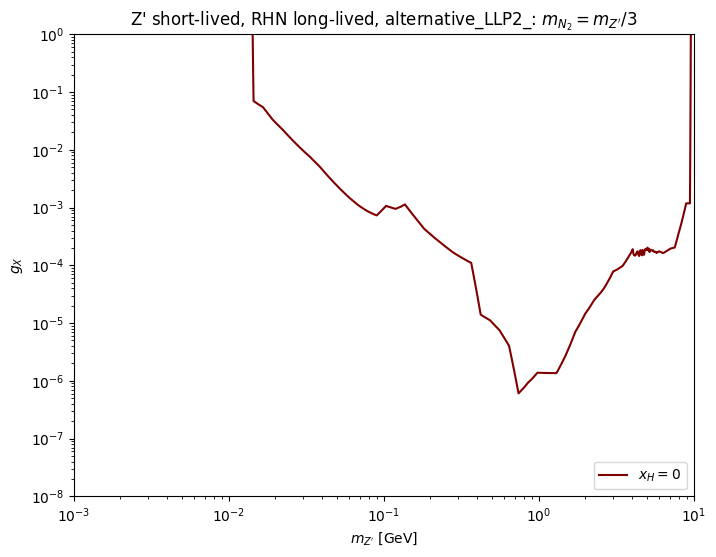

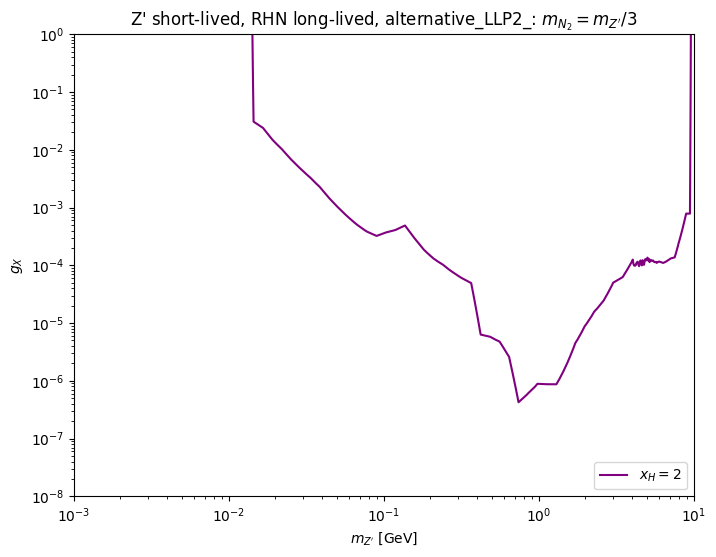

In [22]:
setups = [
         ["100TeV_alternative_LLP2_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_12n.npy",    r"$x_H = -1,2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP2_0.npy",    r"$x_H = 0$"  , "maroon", "solid", 0., 3],#*150/3000]]  
         ["100TeV_alternative_LLP2_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-8, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative_LLP2_: $m_{N_2} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_mu/plots/"+filename+".png")

In [23]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 400, 30000
energy, setup, name = '100', "default_LLP1_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=1, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min 4s, sys: 32.2 ms, total: 9min 4s
Wall time: 9min 4s


In [24]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 46.9 s, sys: 1.38 s, total: 48.3 s
Wall time: 48.3 s


In [25]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/530912224.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


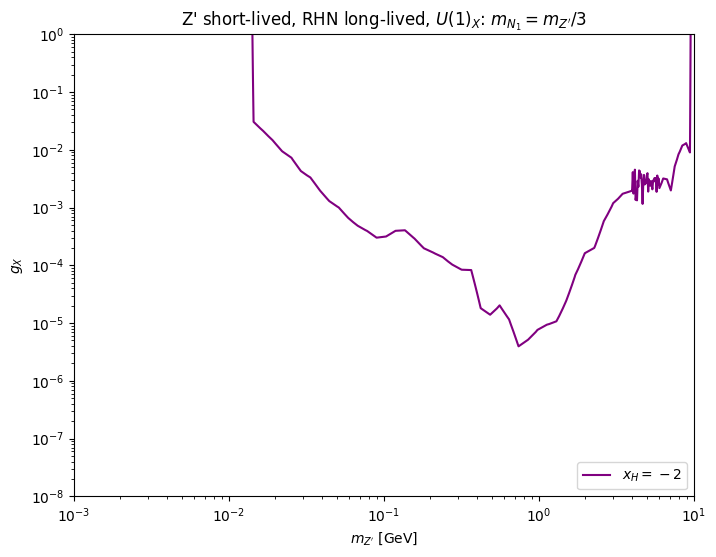

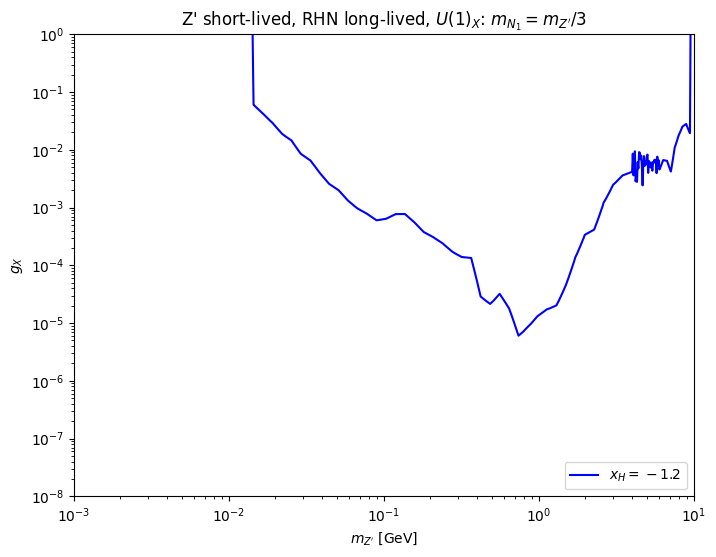

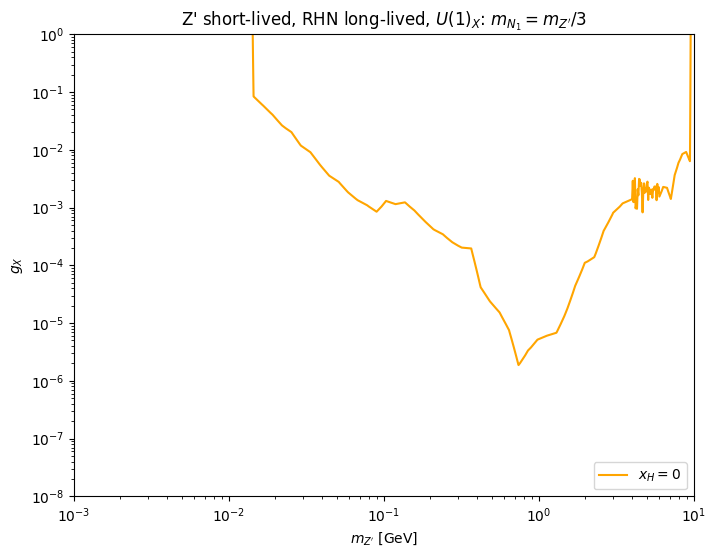

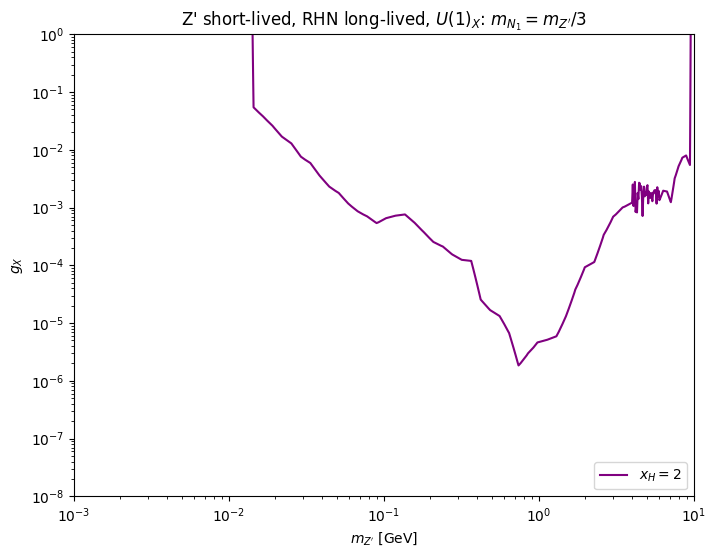

In [26]:
setups = [
         ["100TeV_default_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000],  
         ["100TeV_default_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    # ax.set_ylim(1e-6, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, $U(1)_X$: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_e/plots/"+filename+".png")

In [27]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "default_LLP1_", "U1_X"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=2, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 8min 58s, sys: 52 ms, total: 8min 58s
Wall time: 8min 58s


In [28]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 1min 16s, sys: 1.72 s, total: 1min 18s
Wall time: 1min 18s


In [29]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/845557657.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


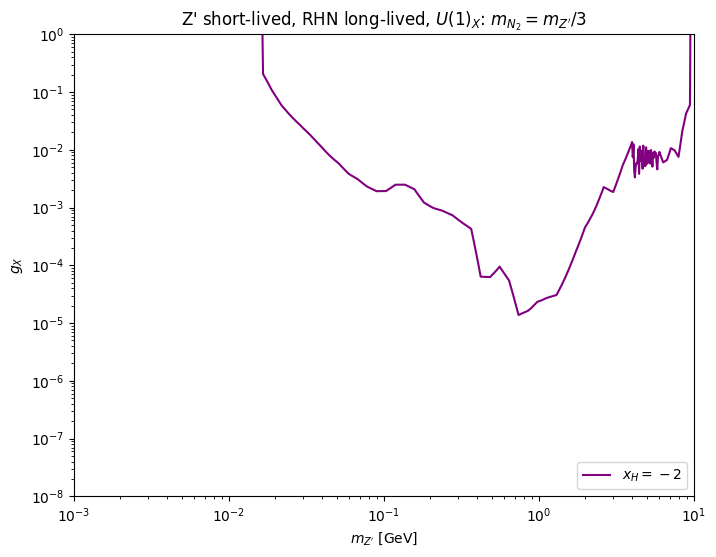

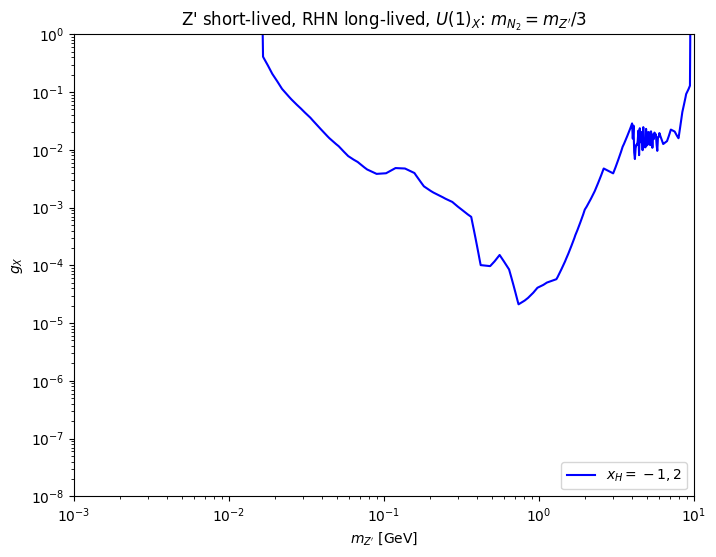

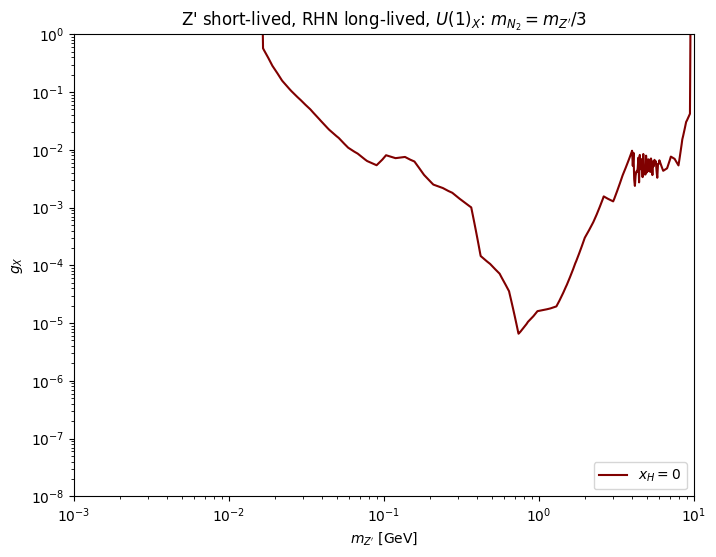

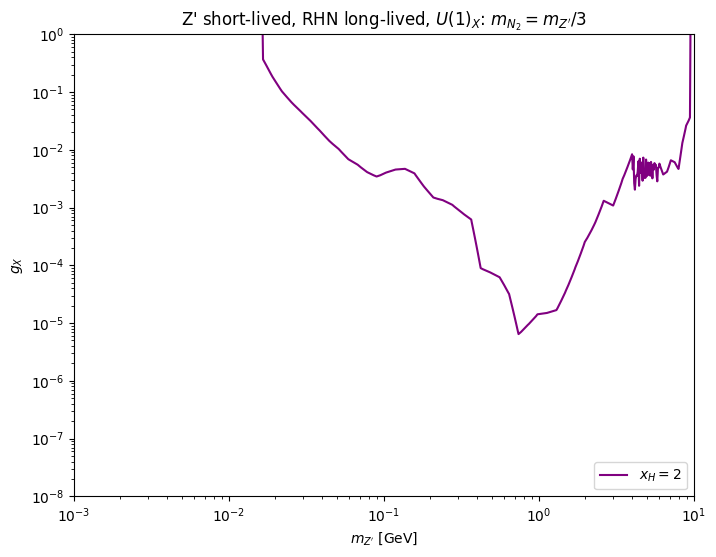

In [30]:
setups = [
         ["100TeV_default_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_12n.npy",    r"$x_H = -1,2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_default_LLP1_0.npy",    r"$x_H = 0$"  , "maroon", "solid", 0., 3],#*150/3000]]  
         ["100TeV_default_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-8, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, $U(1)_X$: $m_{N_2} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_mu/plots/"+filename+".png")

In [31]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "alternative_LLP1_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=1, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min 7s, sys: 40.1 ms, total: 9min 7s
Wall time: 9min 7s


In [32]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 1min 28s, sys: 1.58 s, total: 1min 29s
Wall time: 1min 30s


In [33]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_e/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/3687043000.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


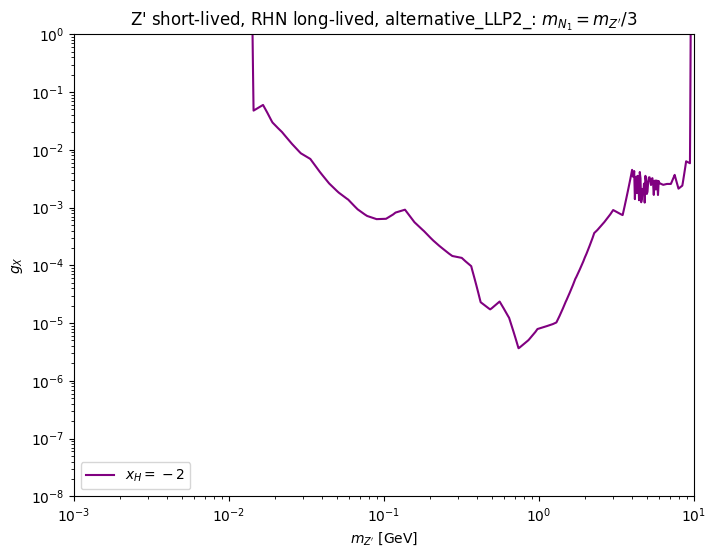

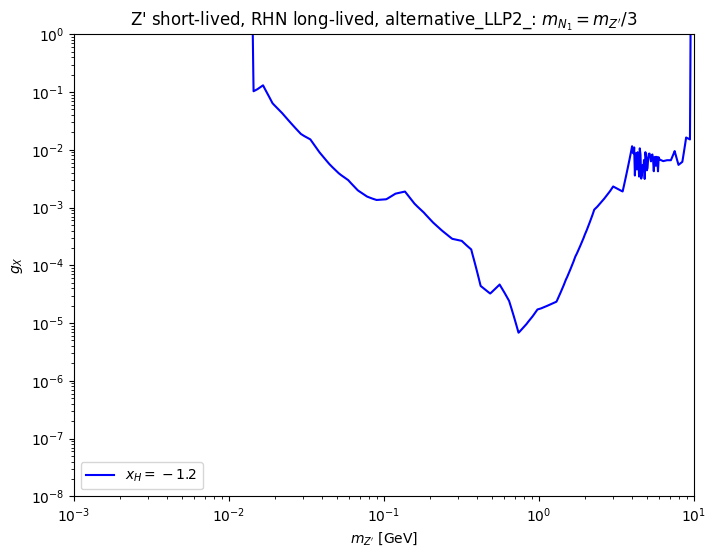

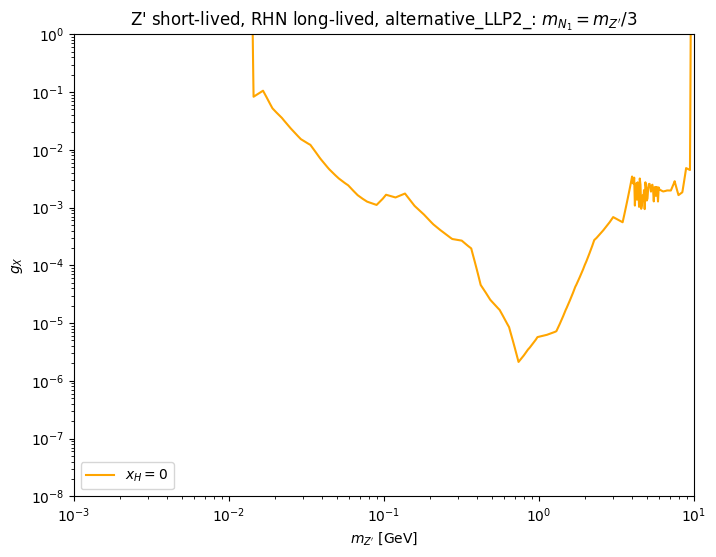

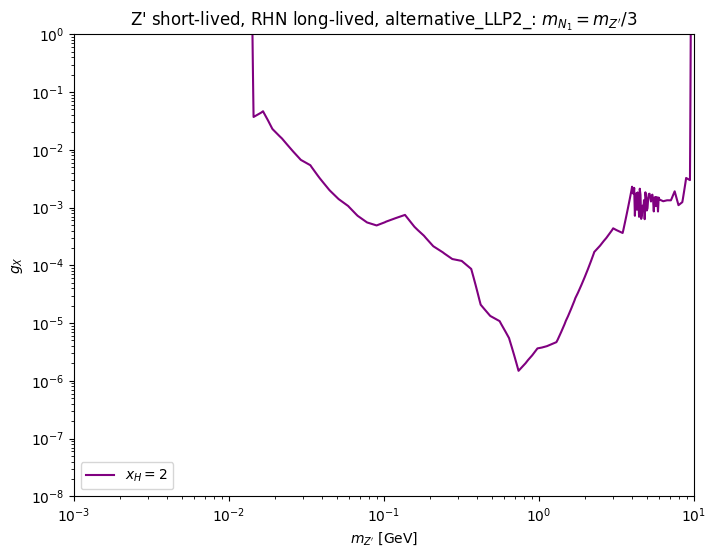

In [34]:
setups = [
         ["100TeV_alternative_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_12n.npy",    r"$x_H = -1.2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_0.npy",    r"$x_H = 0$"  , "orange", "solid", 0., 3],#*150/3000], 
         ["100TeV_alternative_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_e/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-8, 1)
    ax.legend(loc = "lower left")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative_LLP2_: $m_{N_1} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_e/plots/"+filename+".png")

In [35]:
%%time
distance, selection, length, luminosity = 1500, "abs(x.x)<2.5 and abs(x.y)<2.5", 50, 30000
energy, setup, name = '100', "alternative_LLP1_", "U1_X_phi4"

foresee.set_detector(distance=distance, selection=selection, length=length, luminosity=luminosity, name=name)

foresee.slp_event_gen(masses, energy, N=2, modes=None, nsample=10, U=1e-3, sample=1, mN = 1/3,
                      preselectioncuts="th<np.sqrt(12.5)/1500", coup_ref=1, extend_to_low_pt_scales={})

CPU times: user 9min 1s, sys: 80.2 ms, total: 9min 1s
Wall time: 9min 1s


In [36]:
%%time
#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-1, model1="U1_X_phi4_1n", model0="B-L_boson", energy=energy,
                                    couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
    list_nevents.append(nevents)  
        
#save results
np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"1n.npy",[masses,couplings,list_nevents])

CPU times: user 1min 28s, sys: 1.66 s, total: 1min 29s
Wall time: 1min 30s


In [37]:
# %%time
# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH=-2, model1="U1_X_phi4_2n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings = foresee.get_events_slp(nsample=10, mass=mass, xH = -1.2, model1="U1_X_phi4_12n", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"12n.npy",[masses,couplings,list_nevents])


# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH = 0, model1="U1_X_phi4_0", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
    
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"0.npy",[masses,couplings,list_nevents])

# #get reach  
# list_nevents = []    
# #masses = np.logspace(-2, 1, 50)
# for mass in masses:
#     nevents, couplings  = foresee.get_events_slp(nsample=10, mass=mass, xH=2, model1="U1_X_phi4_2p", model0="B-L_boson", energy=energy,
#                                     couplings = np.logspace(-8,0,60), mN1=1/3, mN2=1/3, mN3=1000)
#     list_nevents.append(nevents)  
        
# #save results
# np.save("model/results_RHN3_mu/"+energy+"TeV_"+setup+"2p.npy",[masses,couplings,list_nevents])

/tmp/ipykernel_32553/3745257076.py:14: UserWarning: The following kwargs were not used by contour: 'clabel'
  ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


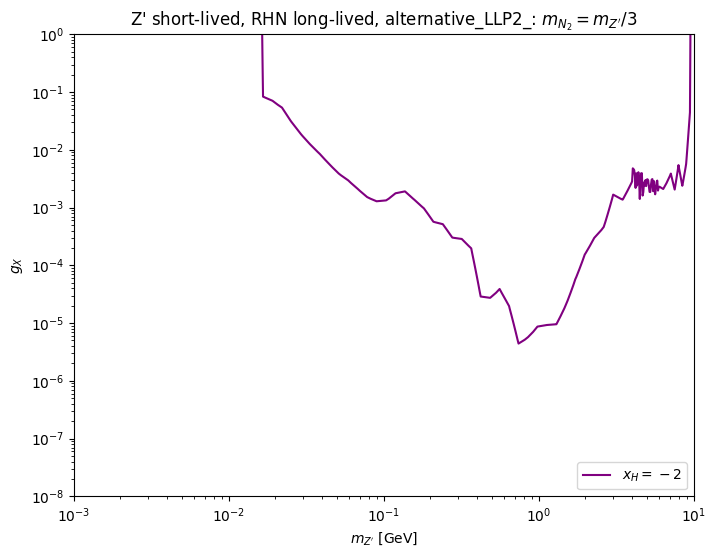

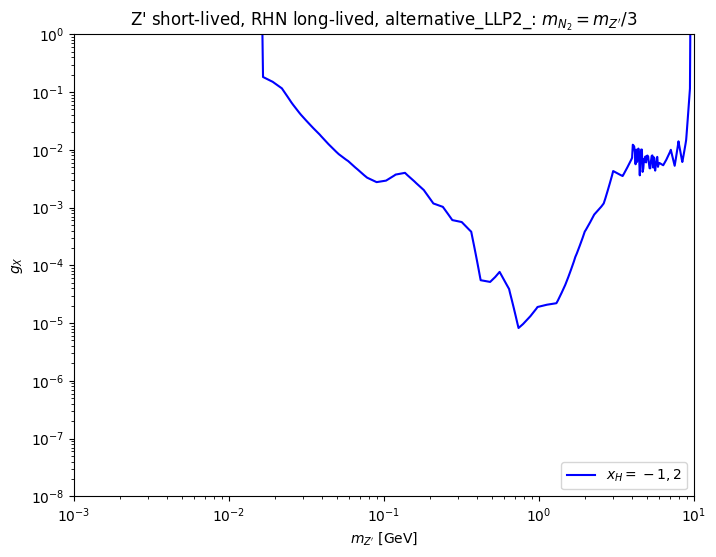

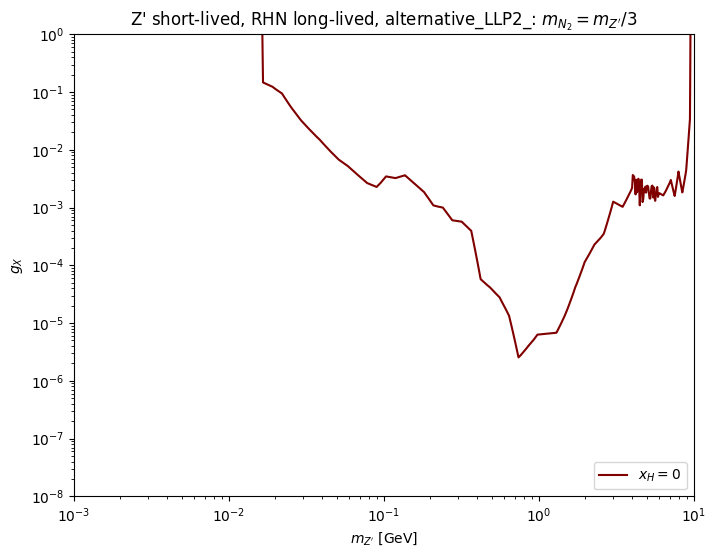

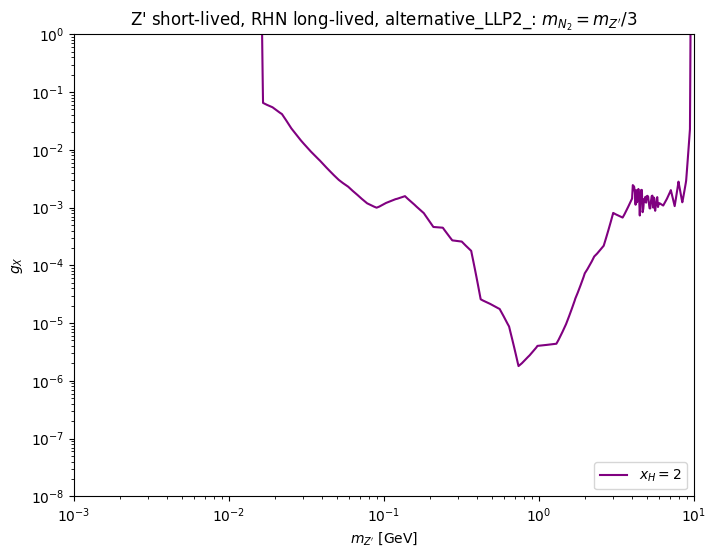

In [38]:
setups = [
         ["100TeV_alternative_LLP1_2n.npy",    r"$x_H = -2$"  , "purple", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_12n.npy",    r"$x_H = -1,2$"  , "blue", "solid", 0., 3],#*150/3000],
         ["100TeV_alternative_LLP1_0.npy",    r"$x_H = 0$"  , "maroon", "solid", 0., 3],#*150/3000]]  
         ["100TeV_alternative_LLP1_2p.npy",    r"$x_H = 2$"  , "purple", "solid", 0., 3]#*150/3000]]
]

for setup in setups:
    fig, ax = plt.subplots()
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load(model.modelpath+"model/results_RHN3_mu/"+filename, allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings)
    n = np.log10(np.array(nsignals).T+1e-20)
    ax.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    ax.plot([0],[0],label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$m_{Z'}$ [GeV]") 
    ax.set_ylabel(r"$g_X$")
    plt.rcParams["figure.figsize"]=(8,6)
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-8, 1)
    ax.legend(loc = "lower right")
    ax.set_title(r"Z' short-lived, RHN long-lived, alternative_LLP2_: $m_{N_2} = m_{Z'}/3$")
    plt.savefig(model.modelpath+"model/results_RHN3_mu/plots/"+filename+".png")